## PageRank y HITS: Grafo

- Se define y justifica el grafo sobre el que corren PageRank y HITS (nodos, aristas, dirección y peso)

- Spark para las estadísticas del bipartito; local (scipy) para componentes y comparaciones, porque 89k nodos y 136k aristas caben en una matriz dispersa

### Constantes

- `RANGO_PESO`: pesos de arista que se comparan

In [5]:
RANGO_PESO = ["binario", "n_adj", "log_monto", "monto"]

### Utilidades

In [6]:
%cd /home/jovyan/work/04_PAGERANKHITS

/home/jovyan/work/04_PAGERANKHITS


In [7]:
NOTEBOOK = "a_grafo"
%run ../funciones.ipynb
%run funciones.ipynb

In [8]:
spark = crear_spark(NOTEBOOK)
verificar_cluster(spark)

Master        : spark://spark-master:7077
Executors     : 2
Cores totales : 2
Memoria driver: 2.0 GB
UI del job    : http://localhost:4040


### Carga

`grafo_bipartito` de `01_Trans/c_uso`: arista entidad → proveedor si hubo ≥ 1 adjudicación, con `n_adj` y `monto`

In [9]:
v_s = leer(artef_dir, "grafo_bipartito/vertices")
a_s = leer(artef_dir, "grafo_bipartito/aristas").cache()
print(f"vértices: {v_s.count():,} | aristas: {a_s.count():,}")

vértices: 89,030 | aristas: 136,132


---
### **1. Estructura del bipartito**

In [10]:
lado = lambda col: a_s.groupBy(F.col(col).alias("id")).agg(F.count("*").alias("grado"), F.sum("n_adj").alias("fuerza"),
                                                            F.sum("monto").alias("monto"))
grados = lado("src").unionByName(lado("dst")).join(v_s.select("id", "tipo"), "id").cache()
q = {t: grados.where(F.col("tipo") == t).approxQuantile("grado", [.5, .9, .99], .001) for t in ("entidad", "proveedor")}
n = dict(grados.groupBy("tipo").count().collect())
m = a_s.count()
resumen = pd.DataFrame([
    ("entidades", n["entidad"]), ("proveedores", n["proveedor"]), ("aristas", m),
    ("densidad (aristas / (E × P))", m / (n["entidad"] * n["proveedor"])),
    ("grado entidad p50", q["entidad"][0]), ("grado entidad p99", q["entidad"][2]),
    ("grado proveedor p50", q["proveedor"][0]), ("grado proveedor p99", q["proveedor"][2]),
    ("% proveedores con 1 entidad", 100 * grados.where("tipo = 'proveedor' AND grado = 1").count() / n["proveedor"]),
    ("% aristas con 1 adjudicación", 100 * a_s.where("n_adj = 1").count() / m)], columns=["medida", "valor"])
resumen

,medida,valor
0,entidades,2992.000000
1,proveedores,86038.000000
2,aristas,136132.000000
3,densidad (aristas / (E × P)),0.000529
4,grado entidad p50,19.000000
5,grado entidad p99,399.000000
6,grado proveedor p50,1.000000
7,grado proveedor p99,11.000000
8,% proveedores con 1 entidad,84.886910
9,% aristas con 1 adjudicación,79.789469


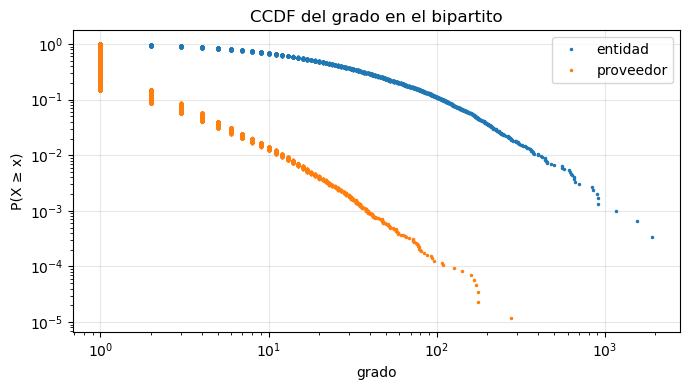

In [11]:
g = grados.select("tipo", "grado").toPandas()
fig, ax = plt.subplots(figsize=(7, 4))
for t, d in g.groupby("tipo"):
    x = np.sort(d.grado.to_numpy())
    ax.loglog(x, 1 - np.arange(len(x)) / len(x), ".", ms=3, label=t)
ax.set(xlabel="grado", ylabel="P(X ≥ x)", title="CCDF del grado en el bipartito"); ax.legend()
mostrar_fig("ccdf_grado")

- **Bipartito muy disperso:** densidad **XX**; el **XX%** de los proveedores vende a una sola entidad

- **Cola pesada** en los dos lados (CCDF casi recta en log-log): pocos actores concentran las relaciones, así que la centralidad discrimina

- **XX%** de las aristas son de una sola adjudicación: por eso el peso `n_adj` separa relaciones recurrentes de esporádicas

---
### **2. Componentes conexas**

In [12]:
v, a, n_e = cargar_bipartito()
n_p = len(v) - n_e
M_bin = matriz_grafo(matriz_bip(a, n_e, n_p, "binario"), dirigido=False)
n_comp, comp = connected_components(M_bin, directed=False)
v["componente"] = comp
tam = v.groupby("componente").agg(nodos=("idx", "size"), entidades=("tipo", lambda t: int((t == "entidad").sum())))
gigante = tam.nodos.idxmax()
v["en_gigante"] = (v.componente == gigante).astype(int)
a["en_gigante"] = v.en_gigante.to_numpy()[a.i]
componentes = pd.DataFrame([
    ("componentes", n_comp),
    ("% nodos en la gigante", 100 * v.en_gigante.mean()),
    ("% entidades en la gigante", 100 * v.loc[v.tipo == "entidad", "en_gigante"].mean()),
    ("% aristas en la gigante", 100 * a.en_gigante.mean()),
    ("% monto en la gigante", 100 * a.loc[a.en_gigante == 1, "monto"].sum() / a.monto.sum()),
    ("tamaño mediano de las demás", tam.drop(gigante).nodos.median()),
    ("entidades fuera de la gigante", tam.drop(gigante).entidades.sum())], columns=["medida", "valor"])
componentes

,medida,valor
0,componentes,193.000000
1,% nodos en la gigante,99.005953
2,% entidades en la gigante,93.516043
3,% aristas en la gigante,99.490935
4,% monto en la gigante,99.725077
5,tamaño mediano de las demás,4.000000
6,entidades fuera de la gigante,194.000000


- **XX componentes**: la gigante reúne el **XX%** de los nodos y el **XX%** del monto

- Las demás son **estrellas chicas**: una entidad con proveedores que solo le venden a ella

- **Consecuencia para PageRank:** el grafo es reducible; sin teletransporte no hay distribución estacionaria única

- **Consecuencia para HITS:** el puntaje se concentra en la gigante y fuera de ella tiende a 0 (se ve en `c_hits`)

- **Local:** `connected_components` de scipy es O(N + E) y tarda < 1 s; en GraphFrames exige checkpoint y varias pasadas

---
### **3. ¿Dirigido o no dirigido?**

- **Dirigido E → P** (como se exportó): las entidades no reciben aristas y los proveedores no emiten, así que todos son **colgantes**

- Con la Google matrix eso da una forma cerrada:
  - PR(entidad) = (1 − d)/N + d·D/N, **igual para todas** (D = masa colgante)
  - PR(proveedor) = PR(entidad)·(1 + d·Σₑ wₑₚ / Wₑ)

- PageRank deja de ser recursivo: ordena a los proveedores por su **suma de cuotas de billetera** Σₑ wₑₚ/Wₑ (cuántas "entidades equivalentes" dependen de él)

- **No dirigido E ↔ P:** el paseo alterna entidad → proveedor → entidad
  - Un proveedor es central si le compran entidades centrales que le dedican buena parte de su compra
  - Una entidad es central si compra a proveedores centrales

In [13]:
W = matriz_bip(a, n_e, n_p, PESO)
r_dir, k_dir, _ = pagerank_local(matriz_grafo(W, dirigido=True))
r_und, k_und, _ = pagerank_local(matriz_grafo(W, dirigido=False))
fuerza = np.asarray(matriz_grafo(W, False).sum(axis=1)).ravel()
cuota = np.asarray((sp.diags(1 / np.asarray(W.sum(axis=1)).ravel()) @ W).sum(axis=0)).ravel()
dirigido = pd.DataFrame([
    ("dirigido E→P", "entidades: (máx − mín) / media del PageRank", np.ptp(r_dir[:n_e]) / r_dir[:n_e].mean()),
    ("dirigido E→P", "proveedores colgantes (sin salida)", n_p),
    ("dirigido E→P", "Spearman proveedor vs Σ cuota de billetera", spearman(r_dir[n_e:], cuota)),
    ("no dirigido", "Spearman entidad vs fuerza", spearman(r_und[:n_e], fuerza[:n_e])),
    ("no dirigido", "Spearman proveedor vs fuerza", spearman(r_und[n_e:], fuerza[n_e:])),
    ("no dirigido", "iteraciones hasta TOL", k_und)], columns=["grafo", "medida", "valor"])
dirigido

,grafo,medida,valor
0,dirigido E→P,entidades: (máx − mín) / media del PageRank,0.000000
1,dirigido E→P,proveedores colgantes (sin salida),86038.000000
2,dirigido E→P,Spearman proveedor vs Σ cuota de billetera,1.000000
3,no dirigido,Spearman entidad vs fuerza,0.969790
4,no dirigido,Spearman proveedor vs fuerza,0.698559
5,no dirigido,iteraciones hasta TOL,146.000000


- **Dirigido:** las entidades quedan empatadas (rango relativo ≈ 0) y el ranking de proveedores coincide al 100% con la suma de cuotas (Spearman = 1)

- Esa suma **sí es útil para PQ1**: mide dependencia, no centralidad, y se guarda como `cuota_billetera`

- **No dirigido:** muy correlacionado con la fuerza (Spearman **XX**), pero no idéntico; las desviaciones (actores más o menos centrales que su volumen) son la señal que se analiza en `d_analisis`

| Variante | Entidades | Proveedores | Uso |
|---|---|---|---|
| Dirigido E → P | todas iguales | = Σ cuota de billetera | métrica de **dependencia** (`cuota_billetera`) |
| **No dirigido E ↔ P** | recursivo | recursivo | **PageRank principal** |
| Bipartito E → P (matriz A) | hubs | authorities | **HITS** |

---
### **4. Peso de las aristas**

In [14]:
m_ = a.monto.fillna(0).to_numpy()
monto_nodo = np.r_[np.bincount(a.i, m_, n_e), np.bincount(a.j, m_, n_p)]
grado = np.asarray(M_bin.sum(axis=1)).ravel()
pr_peso = {p: pagerank_local(matriz_grafo(matriz_bip(a, n_e, n_p, p), False))[0] for p in RANGO_PESO}
P_ = slice(n_e, None)
eleccion = pd.DataFrame([{"peso": p, "spearman_grado": spearman(r[P_], grado[P_]), "spearman_monto": spearman(r[P_], monto_nodo[P_]),
                          "top20_vs_grado": top_jaccard(r[P_], grado[P_]), "top20_vs_monto": top_jaccard(r[P_], monto_nodo[P_]),
                          "spearman_vs_n_adj": spearman(r[P_], pr_peso["n_adj"][P_])} for p, r in pr_peso.items()]).round(3)
eleccion

,peso,spearman_grado,spearman_monto,top20_vs_grado,top20_vs_monto,spearman_vs_n_adj
0,binario,0.618,0.200,0.739,0.000,0.825
1,n_adj,0.564,0.263,0.538,0.026,1.000
2,log_monto,0.611,0.511,0.739,0.026,0.791
3,monto,0.305,0.856,0.333,0.176,0.358


- **`monto`:** el PageRank copia el ranking de monto (Spearman **XX**, top-20 **XX**); no aporta frente a sumar montos y las megaobras dominan

- **`binario`:** casi igual al grado (Spearman **XX**)

- **`n_adj` (elegido):** mide la **recurrencia** de la relación, no su tamaño; así el contraste centralidad vs monto que pedía el EDA es informativo

- **`log_monto`:** queda como robustez; su ranking coincide con `n_adj` en **XX** (Spearman)

---
### **5. Exportación a `temp/datos/`**

- `nodos.parquet`: idx, tipo, nombre, componente, grado, fuerza (`n_adj`), monto y `cuota_billetera`

- `aristas.parquet`: índices enteros (i = entidad, j = proveedor) con `n_adj` y `monto`

In [15]:
v["clave"] = v.id.str[2:]
v["grado"], v["fuerza"], v["monto"] = grado.astype(int), fuerza, monto_nodo
v["cuota_billetera"] = np.r_[np.full(n_e, np.nan), cuota]
v.to_parquet(datos_dir / "nodos.parquet", index=False)
a[["i", "j", "n_adj", "monto", "anio_min", "anio_max", "en_gigante"]].to_parquet(datos_dir / "aristas.parquet", index=False)
guardar_config({"n_e": n_e, "n_p": n_p, "peso": PESO, "componentes": int(n_comp)})
print(f"temp/datos: nodos ({len(v):,}), aristas ({len(a):,}), config.json")

temp/datos: nodos (89,030), aristas (136,132), config.json


---
### **6. Escritura de resultados**

In [16]:
escritos = guardar_tablas({"resumen_grafo": resumen, "componentes": componentes, "dirigido_vs_no_dirigido": dirigido,
                           "eleccion_peso": eleccion,
                           "grado_bipartito": g.groupby(["tipo", "grado"]).size().reset_index(name="nodos")})

Escrito en 04_PAGERANKHITS/temp/a_grafo/: resumen_grafo, componentes, dirigido_vs_no_dirigido, eleccion_peso, grado_bipartito


#### a. Verificación

In [17]:
verificar_salidas(escritos)
assert abs(r_und.sum() - 1) < 1e-9 and (r_und > 0).all(), "PageRank no es una distribución"
assert spearman(r_dir[n_e:], cuota) > 0.999, "la forma cerrada del dirigido no se cumple"
print("PageRank suma 1 | dirigido = Σ cuota de billetera")

OK: 5 tablas (parquet + json) | 1 figuras: ccdf_grado
PageRank suma 1 | dirigido = Σ cuota de billetera


---
### **7. Cerrar sesión**

In [18]:
spark.stop()